# Challenge Motiva + FIAP | Dynamic Programming
**Projeto:** Priorização e roteirização de manutenção de escadas rolantes da ViaQuatro  

**Escopo:** histórico de manutenção SAP, índice de criticidade por regras transparentes, roteirização e plano de turno. Alinhado ao Project Charter CP3 do grupo.

> **ATENÇÃO — EXECUÇÃO DEMONSTRATIVA:** os arquivos reais do SAP não foram anexados. Este notebook executa sobre `ocorrencias_demo.csv`, gerado artificialmente. Nenhum ranking ou resultado numérico desta execução representa a Motiva. Substitua pelo arquivo real normalizado antes da entrega final. A proposta do enunciado menciona sensores, mas o Charter informa que o dataset entregue contém histórico de manutenção, sem vibração, temperatura, corrente, óleo ou velocidade. A adaptação da função de degradação exige validação do professor.

## 1. Dados e metodologia
Entradas: `dados/ocorrencias_demo.csv` (demonstração), `dados/escadas_estacoes.csv` (vínculo **ilustrativo** escada-estação) e `dados/rede_estacoes.csv` (grafo com tempos **ilustrativos**). As estações são da Linha 4-Amarela; os tempos não são tempos operacionais aferidos. A base escolhida é Luz, por hipótese didática, e não representa a localização real de uma base de manutenção.

A degradação acumulada é uma **pontuação de priorização**, não degradação física nem probabilidade de falha. Para cada ocorrência, usa-se `peso = 5·I(corretiva) + 2·horas_indisponibilidade + 1·horas_mao_obra + 4·I(reincidente_30d)`. Coeficientes são hipóteses didáticas, ajustáveis após validação técnica. Acumulação temporal: `D(i)=D(i-1)+peso(i)`, com `D(0)=0`. Não se supõe recuperação do desgaste após manutenção. Eventos com dados ausentes não devem ser imputados silenciosamente.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import time, math, heapq
from collections import deque
from functools import lru_cache
import matplotlib.pyplot as plt

BASE = Path('dados') if Path('dados').exists() else Path('Motiva_Dynamic_Programming/dados')
ARQUIVO_OCORRENCIAS = BASE / 'ocorrencias_demo.csv'  # TROCAR por ocorrencias_reais_tratadas.csv
MODO_DEMONSTRACAO = ARQUIVO_OCORRENCIAS.name == 'ocorrencias_demo.csv'
print('MODO DEMONSTRAÇÃO:', MODO_DEMONSTRACAO)
oc = pd.read_csv(ARQUIVO_OCORRENCIAS, parse_dates=['data'])
mapa = pd.read_csv(BASE/'escadas_estacoes.csv')
rede = pd.read_csv(BASE/'rede_estacoes.csv')
print('Ocorrências:',oc.shape,'| Escadas:',oc.escada_id.nunique())
display(oc.head())

MODO DEMONSTRAÇÃO: True
Ocorrências: (166, 6) | Escadas: 24


,escada_id,data,tipo_ocorrencia,horas_indisponibilidade,horas_mao_obra,reincidente_30d
0,E001,2026-02-04,corretiva,3.96,2.45,0
1,E001,2026-03-07,corretiva,0.34,3.99,0
2,E001,2026-04-10,preventiva,0.25,3.58,0
3,E001,2026-05-13,corretiva,1.03,2.43,1
4,E001,2026-06-16,corretiva,5.92,2.34,0


### Contrato de entrada real
O CSV normalizado deve conter `escada_id`, `data`, `tipo_ocorrencia`, `horas_indisponibilidade`, `horas_mao_obra`, `reincidente_30d`. Os dados originais SAP (notas, IW47, MB51) precisam ser mapeados para esse esquema, com anonimização de nomes/matrículas e separação das paradas por passageiros. **Não use as correspondências ilustrativas de escada-estação como verdade operacional.**

In [ ]:
required={'escada_id','data','tipo_ocorrencia','horas_indisponibilidade','horas_mao_obra','reincidente_30d'}
assert required.issubset(oc.columns), f'Faltam colunas: {required-set(oc.columns)}'
assert not oc[list(required)].isna().any().any(), 'Existem nulos: investigar antes do cálculo'
assert (oc[['horas_indisponibilidade','horas_mao_obra']] >= 0).all().all()
assert oc['reincidente_30d'].isin([0,1]).all()
assert oc['tipo_ocorrencia'].isin(['corretiva','preventiva']).all()
assert not oc.duplicated().any(), 'Duplicatas exatas precisam ser investigadas'
oc = oc.sort_values(['escada_id','data']).reset_index(drop=True)
oc['peso'] = (5*oc.tipo_ocorrencia.eq('corretiva').astype(int) + 2*oc.horas_indisponibilidade + oc.horas_mao_obra + 4*oc.reincidente_30d)
print('Validação concluída; soma de pesos:',round(oc.peso.sum(),2))

Validação concluída; soma de pesos: 2192.2


## 2. Três implementações da degradação acumulada
A recursão pura é deliberadamente repetitiva ao calcular toda a sequência de prefixos; a versão memoizada evita recomputações. A tabulação percorre os eventos uma vez. O teste de desempenho usa um subconjunto para evitar recursão excessiva e respeitar o limite de profundidade do Python.

In [ ]:
def recursiva_pura(pesos, i):
    """Retorna o acumulado até o índice i, sem cache (O(i) por consulta)."""
    if i < 0: return 0.0
    return float(pesos[i]) + recursiva_pura(pesos, i-1)

def recursiva_memoizada(pesos):
    """Calcula todos os prefixos usando cache explícito em dicionário."""
    memo = {-1: 0.0}
    def acum(i):
        if i not in memo: memo[i] = float(pesos[i]) + acum(i-1)
        return memo[i]
    return [acum(i) for i in range(len(pesos))]

def tabulacao(pesos):
    """Calcula todos os prefixos iterativamente, em O(n)."""
    tabela=[]; total=0.0
    for p in pesos:
        total+=float(p); tabela.append(total)
    return tabela

def sequencia_pura(pesos):
    return [recursiva_pura(pesos,i) for i in range(len(pesos))]

pesos=oc.loc[oc.escada_id==oc.escada_id.iloc[0],'peso'].to_numpy()[:15]
a,b,c=sequencia_pura(pesos),recursiva_memoizada(pesos),tabulacao(pesos)
assert np.allclose(a,b) and np.allclose(b,c)
print('Três versões equivalentes. Acumulado:',round(c[-1],2))

Três versões equivalentes. Acumulado: 120.79


algoritmo,Memoização,Recursiva pura,Tabulação
leituras,,,
10,0.0061,0.0108,0.0056
30,0.0320,0.0644,0.0054
60,0.0134,0.1582,0.0054
100,0.0210,0.4298,0.0077
150,0.0317,1.5392,0.0127


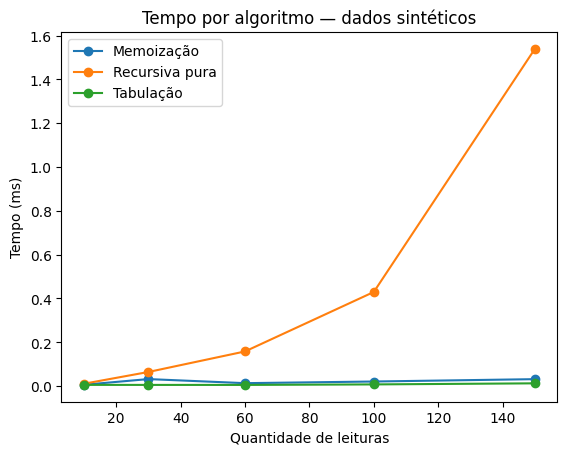

Interpretação: recursão pura recalcula prefixos e tende a crescer quadraticamente; memoização e tabulação tendem a crescimento linear. Tempos exatos variam por ambiente.


In [ ]:
medicoes=[]
for n in [10,30,60,100,150]:
    x=np.ones(n)
    for nome,fn in [('Recursiva pura',sequencia_pura),('Memoização',recursiva_memoizada),('Tabulação',tabulacao)]:
        t0=time.perf_counter(); r=fn(x); dur=time.perf_counter()-t0
        assert np.isclose(r[-1],n)
        medicoes.append({'leituras':n,'algoritmo':nome,'tempo_ms':dur*1000})
perf=pd.DataFrame(medicoes)
display(perf.pivot(index='leituras',columns='algoritmo',values='tempo_ms').round(4))
for nome,g in perf.groupby('algoritmo'):
    plt.plot(g.leituras,g.tempo_ms,marker='o',label=nome)
plt.xlabel('Quantidade de leituras');plt.ylabel('Tempo (ms)');plt.title('Tempo por algoritmo — dados sintéticos');plt.legend();plt.show()
print('Interpretação: recursão pura recalcula prefixos e tende a crescer quadraticamente; memoização e tabulação tendem a crescimento linear. Tempos exatos variam por ambiente.')

## 3. Ranking de criticidade
O ranking utiliza o último valor da sequência acumulada de cada escada. **Atenção:** o valor bruto favorece equipamentos com mais registros e tempo de observação; comparar janelas equivalentes antes de qualquer uso real. Não é probabilidade de falha.

,escada_id,criticidade,ocorrencias,posicao
0,E014,137.78,9,1
1,E004,131.19,9,2
2,E008,129.47,9,3
3,E003,126.89,9,4
4,E010,124.84,8,5
5,E001,120.79,9,6
6,E012,119.60,8,7
7,E020,116.83,10,8
8,E005,109.69,10,9
9,E021,95.07,7,10


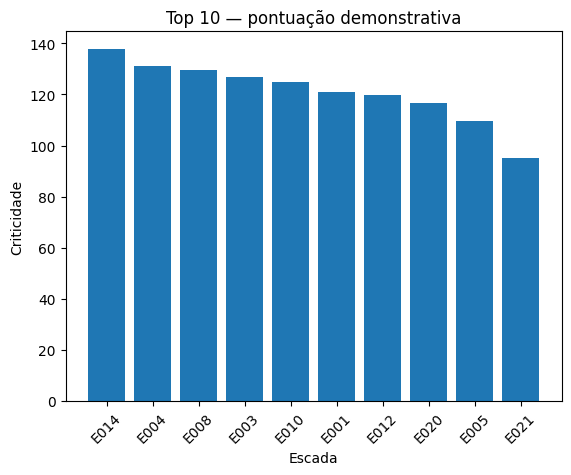

Interpretação: ranking ilustrativo; requer validação de pesos, janelas e critérios de manutenção.


In [ ]:
ranking=[]
for escada,grupo in oc.groupby('escada_id'):
    total=tabulacao(grupo.peso.to_numpy())[-1]
    ranking.append({'escada_id':escada,'criticidade':total,'ocorrencias':len(grupo)})
ranking=pd.DataFrame(ranking).sort_values(['criticidade','escada_id'],ascending=[False,True]).reset_index(drop=True)
ranking['posicao']=np.arange(1,len(ranking)+1)
display(ranking.head(10))
plt.bar(ranking.head(10).escada_id,ranking.head(10).criticidade)
plt.title('Top 10 — pontuação demonstrativa');plt.xlabel('Escada');plt.ylabel('Criticidade');plt.xticks(rotation=45);plt.show()
print('Interpretação: ranking ilustrativo; requer validação de pesos, janelas e critérios de manutenção.')

## 4. Grafo de estações, BFS e Dijkstra
Grafo não direcionado em lista de adjacência. BFS minimiza **quantidade de trechos** e Dijkstra minimiza **minutos**, que são métricas diferentes. Os pesos são positivos e representam hipóteses ilustrativas. A estação Luz é a base hipotética.

In [ ]:
def criar_grafo(arestas):
    """Monta lista de adjacência não direcionada."""
    g={}
    for o,d,m in arestas[['origem','destino','minutos']].itertuples(index=False,name=None):
        if float(m)<=0: raise ValueError('Tempo deve ser positivo')
        g.setdefault(o,[]).append((d,float(m)))
        g.setdefault(d,[]).append((o,float(m)))
    return g

def reconstruir(anterior,origem,destino):
    if destino!=origem and destino not in anterior:return None
    rota=[destino]
    while rota[-1]!=origem:rota.append(anterior[rota[-1]])
    return rota[::-1]

def bfs(g,origem,destino):
    """Caminho com menor número de arestas."""
    if origem not in g or destino not in g:return None
    fila=deque([origem]);visto={origem};prev={}
    while fila:
        u=fila.popleft()
        if u==destino:break
        for v,_ in g[u]:
            if v not in visto:visto.add(v);prev[v]=u;fila.append(v)
    return reconstruir(prev,origem,destino)

def dijkstra(g,origem,destino):
    """Caminho mínimo em minutos; retorna rota e custo."""
    if origem not in g or destino not in g:return None,math.inf
    dist={origem:0.0};prev={};heap=[(0.0,origem)]
    while heap:
        du,u=heapq.heappop(heap)
        if du>dist[u]:continue
        if u==destino:break
        for v,w in g[u]:
            nd=du+w
            if nd<dist.get(v,math.inf):dist[v]=nd;prev[v]=u;heapq.heappush(heap,(nd,v))
    return reconstruir(prev,origem,destino),dist.get(destino,math.inf)

g=criar_grafo(rede);BASE_ESTACAO='Luz'
assert len(g)>=8
assert set(mapa.estacao).issubset(g)
rotas=[]
for destino in g:
    rb=bfs(g,BASE_ESTACAO,destino);rd,tempo=dijkstra(g,BASE_ESTACAO,destino)
    rotas.append({'estacao':destino,'rota_BFS':' → '.join(rb or []),'trechos_BFS':len(rb)-1 if rb else None,'rota_Dijkstra':' → '.join(rd or []),'minutos_Dijkstra':tempo})
rotas=pd.DataFrame(rotas)
display(rotas)
print('Interpretação: neste grafo linear, BFS e Dijkstra encontram a mesma rota; o objetivo otimizado, porém, é diferente.')

,estacao,rota_BFS,trechos_BFS,rota_Dijkstra,minutos_Dijkstra
0,Luz,Luz,0,Luz,0.0
1,Republica,Luz → Republica,1,Luz → Republica,4.0
2,Higienopolis-Mackenzie,Luz → Republica → Higienopolis-Mackenzie,2,Luz → Republica → Higienopolis-Mackenzie,8.0
3,Paulista,Luz → Republica → Higienopolis-Mackenzie → Pau...,3,Luz → Republica → Higienopolis-Mackenzie → Pau...,11.0
4,Oscar Freire,Luz → Republica → Higienopolis-Mackenzie → Pau...,4,Luz → Republica → Higienopolis-Mackenzie → Pau...,15.0
5,Fradique Coutinho,Luz → Republica → Higienopolis-Mackenzie → Pau...,5,Luz → Republica → Higienopolis-Mackenzie → Pau...,18.0
6,Faria Lima,Luz → Republica → Higienopolis-Mackenzie → Pau...,6,Luz → Republica → Higienopolis-Mackenzie → Pau...,22.0
7,Pinheiros,Luz → Republica → Higienopolis-Mackenzie → Pau...,7,Luz → Republica → Higienopolis-Mackenzie → Pau...,25.0
8,Butanta,Luz → Republica → Higienopolis-Mackenzie → Pau...,8,Luz → Republica → Higienopolis-Mackenzie → Pau...,29.0
9,Sao Paulo-Morumbi,Luz → Republica → Higienopolis-Mackenzie → Pau...,9,Luz → Republica → Higienopolis-Mackenzie → Pau...,33.0


Interpretação: neste grafo linear, BFS e Dijkstra encontram a mesma rota; o objetivo otimizado, porém, é diferente.


## 5. A* e comparação com Dijkstra
Heurística escolhida: **h(n)=0 minutos**, limite inferior admissível e consistente, válido sem coordenadas ou limites de velocidade confiáveis. Essa escolha torna A* equivalente a Dijkstra e não promete ganhos de desempenho. É uma comparação metodologicamente correta; para um A* informativo, é necessário obter distâncias reais e um limite inferior justificável de minutos.

In [ ]:
def a_estrela(g,origem,destino,heuristica=None):
    """A* com heurística admissível fornecida; retorna rota, custo e expansões."""
    if origem not in g or destino not in g:return None,math.inf,0
    h=heuristica or (lambda no,alvo:0.0)
    fila=[(float(h(origem,destino)),0.0,origem)]
    custos={origem:0.0};anterior={};expansoes=0
    while fila:
        _,custo,u=heapq.heappop(fila)
        if custo>custos[u]:continue
        expansoes+=1
        if u==destino:return reconstruir(anterior,origem,destino),custo,expansoes
        for v,peso in g[u]:
            novo=custo+peso
            if novo<custos.get(v,math.inf):
                custos[v]=novo;anterior[v]=u
                heapq.heappush(fila,(novo+float(h(v,destino)),novo,v))
    return None,math.inf,expansoes

comparacao=[]
for destino in g:
    rd,td=dijkstra(g,BASE_ESTACAO,destino)
    ra,ta,exp=a_estrela(g,BASE_ESTACAO,destino)
    assert np.isclose(td,ta) and rd==ra
    comparacao.append({'destino':destino,'minutos_Dijkstra':td,'minutos_A_estrela':ta,'nos_expandidos_A_estrela':exp})
display(pd.DataFrame(comparacao))
print('Interpretação: A* com heurística nula devolve o mesmo ótimo do Dijkstra. Não há evidência de aceleração sem heurística espacial válida.')

,destino,minutos_Dijkstra,minutos_A_estrela,nos_expandidos_A_estrela
0,Luz,0.0,0.0,1
1,Republica,4.0,4.0,2
2,Higienopolis-Mackenzie,8.0,8.0,3
3,Paulista,11.0,11.0,4
4,Oscar Freire,15.0,15.0,5
5,Fradique Coutinho,18.0,18.0,6
6,Faria Lima,22.0,22.0,7
7,Pinheiros,25.0,25.0,8
8,Butanta,29.0,29.0,9
9,Sao Paulo-Morumbi,33.0,33.0,10


Interpretação: A* com heurística nula devolve o mesmo ótimo do Dijkstra. Não há evidência de aceleração sem heurística espacial válida.


## 6. Planejamento integrado do turno
Heurística gulosa: a cada etapa, escolhe a escada de maior criticidade ainda viável no tempo restante, considerando deslocamento **desde a posição atual**, atendimento e retorno à base. Não é garantia de solução global ótima. Tempo padrão por atendimento = 30 minutos, **estimativa demonstrativa**, não duração real de serviço. Não substitui regras de segurança, disponibilidade de equipes, janelas operacionais ou validação da engenharia.

In [ ]:
def planejar_turno(base,horas,tempo_atendimento=30):
    """Planeja visitas por criticidade com orçamento em minutos, incluindo retorno à base."""
    if base not in g:raise ValueError('Base desconhecida')
    if horas<=0 or tempo_atendimento<=0:raise ValueError('Horas e atendimento devem ser positivos')
    itens=ranking.merge(mapa,on='escada_id',how='left',validate='one_to_one')
    if itens.estacao.isna().any():raise ValueError('Escadas sem estação vinculada')
    restantes=itens.to_dict('records');posicao=base;orcamento=horas*60;gasto=0.0;plano=[]
    while restantes:
        viaveis=[]
        for item in restantes:
            rota,ida=dijkstra(g,posicao,item['estacao'])
            _,volta=dijkstra(g,item['estacao'],base)
            if math.isfinite(ida+volta) and gasto+ida+tempo_atendimento+volta<=orcamento+1e-9:
                viaveis.append((item,rota,ida))
        if not viaveis:break
        item,rota,ida=max(viaveis,key=lambda x:(x[0]['criticidade'],-x[2],x[0]['escada_id']))
        gasto+=ida+tempo_atendimento
        plano.append({'ordem':len(plano)+1,'escada_id':item['escada_id'],'estacao':item['estacao'],
                      'criticidade':round(item['criticidade'],2),'trajeto':' → '.join(rota),
                      'deslocamento_min':ida,'atendimento_min':tempo_atendimento,'minutos_acumulados':gasto})
        posicao=item['estacao'];restantes=[x for x in restantes if x['escada_id']!=item['escada_id']]
    volta_rota,volta=dijkstra(g,posicao,base)
    gasto+=volta
    assert gasto<=orcamento+1e-9
    return pd.DataFrame(plano),{'tempo_total_min':round(gasto,2),'tempo_disponivel_min':orcamento,
                                 'retorno_base':' → '.join(volta_rota),'escadas_atendidas':len(plano)}

plano,resumo=planejar_turno(BASE_ESTACAO,8)
display(plano);print('Resumo do turno:',resumo)
assert resumo['tempo_total_min']<=480
print('Interpretação: o plano respeita a duração e reserva retorno; a ordenação é gulosa, não ótima globalmente.')

,ordem,escada_id,estacao,criticidade,trajeto,deslocamento_min,atendimento_min,minutos_acumulados
0,1,E014,Sao Paulo-Morumbi,137.78,Luz → Republica → Higienopolis-Mackenzie → Pau...,33.0,30,63.0
1,2,E004,Republica,131.19,Sao Paulo-Morumbi → Butanta → Pinheiros → Fari...,29.0,30,122.0
2,3,E008,Higienopolis-Mackenzie,129.47,Republica → Higienopolis-Mackenzie,4.0,30,156.0
3,4,E003,Sao Paulo-Morumbi,126.89,Higienopolis-Mackenzie → Paulista → Oscar Frei...,25.0,30,211.0
4,5,E010,Butanta,124.84,Sao Paulo-Morumbi → Butanta,4.0,30,245.0
5,6,E001,Paulista,120.79,Butanta → Pinheiros → Faria Lima → Fradique Co...,18.0,30,293.0
6,7,E012,Paulista,119.60,Paulista,0.0,30,323.0
7,8,E020,Fradique Coutinho,116.83,Paulista → Oscar Freire → Fradique Coutinho,7.0,30,360.0
8,9,E005,Oscar Freire,109.69,Fradique Coutinho → Oscar Freire,3.0,30,393.0
9,10,E021,Butanta,95.07,Oscar Freire → Fradique Coutinho → Faria Lima ...,14.0,30,437.0


Resumo do turno: {'tempo_total_min': 466.0, 'tempo_disponivel_min': 480, 'retorno_base': 'Butanta → Pinheiros → Faria Lima → Fradique Coutinho → Oscar Freire → Paulista → Higienopolis-Mackenzie → Republica → Luz', 'escadas_atendidas': 10}
Interpretação: o plano respeita a duração e reserva retorno; a ordenação é gulosa, não ótima globalmente.


## 7. Testes de consistência, limitações e conclusão
Os testes abaixo validam casos básicos de rota, ordenação e limite de horas. Resultados demonstrativos **não permitem concluir** quais escadas reais precisam de intervenção. Antes de aplicação: validar vínculo SAP–escada–estação, pesos e tempos, estratificar períodos antes/depois de 2023, diferenciar falhas técnicas de paradas causadas por passageiros e confirmar com a Motiva qualquer mudança no plano preventivo.

In [ ]:
# Teste em grafo com duas alternativas: BFS minimiza trechos; Dijkstra minimiza tempo
g_teste={'A':[('B',10),('C',2)],'B':[('A',10),('D',1)],'C':[('A',2),('E',2)],'E':[('C',2),('D',2)],'D':[('B',1),('E',2)]}
assert bfs(g_teste,'A','D')==['A','B','D']
assert dijkstra(g_teste,'A','D')[1]==6
assert a_estrela(g_teste,'A','D')[1]==6
assert tabulacao([])==[]
assert np.allclose(sequencia_pura([1,2,3]),[1,3,6])
assert np.allclose(recursiva_memoizada([1,2,3]),[1,3,6])
curto,info=planejar_turno(BASE_ESTACAO,0.1)
assert info['tempo_total_min']<=6
print('Testes passaram.')
print('Conclusão: protótipo funcional de apoio à priorização e ao planejamento, condicionado à importação e validação dos dados reais.')

Testes passaram.
Conclusão: protótipo funcional de apoio à priorização e ao planejamento, condicionado à importação e validação dos dados reais.
